In [12]:
import numpy as np

from encode import load_vectors
from paths import DATASETS_DIR

# DATASETS = ["obliq-math", "obliq-writing"]
DATASETS = ["obliq-math"]

ENCODERS = {  # encoder: (query tag, corpus tag), as written by encode.py
    "colbert": ("colbertv2.0_d128_nv32", "colbertv2.0_d128_nv180"),
    "bert": ("bert-base-uncased_d768_nv32", "bert-base-uncased_d768_nv180"),
}
POOLS = {  # vectors of one item -> one vector
    "mean": lambda V: V.mean(axis=0),
    "max": lambda V: V.max(axis=0),
}
POOL = "mean"
NORMALIZE = True


def single_vectors(prefix, pool, normalize):
    vectors, offsets, ids, _ = load_vectors(prefix)
    X = np.stack([POOLS[pool](np.asarray(vectors[a:b], dtype=np.float32))
                  for a, b in zip(offsets[:-1], offsets[1:])])
    if normalize:
        X /= np.linalg.norm(X, axis=1, keepdims=True)
    return X, ids


emb = {}
for ds in DATASETS:
    for enc, (qtag, dtag) in ENCODERS.items():
        Q, qids = single_vectors(DATASETS_DIR / ds / "vec_queries" / enc / qtag, POOL, NORMALIZE)
        X, dids = single_vectors(DATASETS_DIR / ds / "vec_corpus" / enc / dtag, POOL, NORMALIZE)
        emb[ds, enc] = {"Q": Q, "qids": qids, "X": X, "dids": dids}

In [13]:
from paths import RESULTS_DIR
from vibe import build_graph, load_prune, read_graph

ALPHA = 1.0
GRAPH_DIR = RESULTS_DIR / "obliq_beam_graphs"

prune_fns = load_prune(use_gpu=False)
graphs = {}
for (ds, enc), e in emb.items():
    name = f"{ds}-{enc}-{POOL}" + ("-l2" if NORMALIZE else "")
    hoods = read_graph(build_graph(e["X"], name, GRAPH_DIR, prune_fns, alpha=ALPHA))
    graphs[ds, enc] = [hoods[i] for i in range(len(e["X"]))]

obliq-math-colbert-mean-l2: 3,508 sources done, 0 to go -> /Users/pratyushavi/Developer/NYU-CS/Research/Multi-Vector-Search/CODEBASE/results/obliq_beam_graphs/adj-list-obliq-math-colbert-mean-l2-alpha1-euclidean.txt
obliq-math-bert-mean-l2: 3,508 sources done, 0 to go -> /Users/pratyushavi/Developer/NYU-CS/Research/Multi-Vector-Search/CODEBASE/results/obliq_beam_graphs/adj-list-obliq-math-bert-mean-l2-alpha1-euclidean.txt


In [14]:
import pandas as pd

from beam import beam_search, medoid, sq_dists
from evaluate import load_qrels
from search import load_excluded

BEAM_WIDTHS = [10, 20, 50, 100, 200]
K = 10  # results returned


def row_stats(t, ids, rel, ex, knn):
    returned = ids[~np.isin(ids, ex)][:K]
    return {"rel seen": (t["seen"][rel] >= 0).mean(),
            "rel added": (t["inserted"][rel] >= 0).mean(),
            "rel expanded": (t["expanded"][rel] >= 0).mean(),
            "precision": np.isin(returned, rel).sum() / K,
            "knn precision": np.isin(returned, knn).sum() / K}


rows = []
for (ds, enc), e in emb.items():
    X, G = e["X"], graphs[ds, enc]
    index = {d: i for i, d in enumerate(e["dids"])}
    qrels, excluded = load_qrels(ds), load_excluded(ds)
    entry = medoid(X)
    D = sq_dists(e["Q"], X)
    for qi, q in enumerate(e["qids"]):
        if q not in qrels:
            continue
        rel = np.array([index[d] for d in qrels[q]])
        ex = np.array([index[d] for d in excluded.get(q, ()) if d in index], dtype=np.int64)
        D[qi, ex] = np.inf
        knn = np.argsort(D[qi])[:K]
        for L in BEAM_WIDTHS:
            ids, _, t = beam_search(G, X, e["Q"][qi], L, entry)
            rows.append({"dataset": ds, "encoder": enc, "L": L, "query": q, "relevant": len(rel),
                         **row_stats(t, ids, rel, ex, knn)})
stats = pd.DataFrame(rows)

In [15]:
STATS = ["rel seen", "rel added", "rel expanded", "precision", "knn precision"]

table = stats.groupby(["dataset", "encoder", "L"])[["relevant", *STATS]].mean()
table.style.format("{:.3f}").format({"relevant": "{:.1f}"})

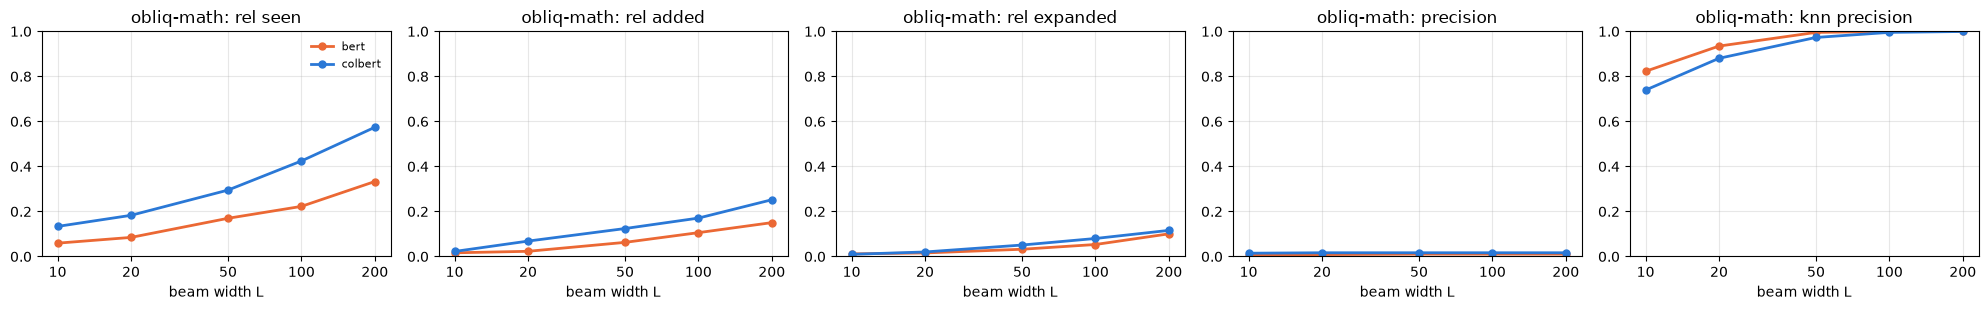

In [16]:
import matplotlib.pyplot as plt

COLORS = {"colbert": "#2a78d6", "bert": "#eb6834"}

fig, axes = plt.subplots(len(DATASETS), len(STATS), figsize=(4 * len(STATS), 3.2 * len(DATASETS)), squeeze=False)
for row, ds in zip(axes, DATASETS):
    for ax, col in zip(row, STATS):
        for enc, s in table.loc[ds, col].groupby(level="encoder"):
            ax.plot(s.index.get_level_values("L"), s.values, marker="o", ms=5, lw=2, color=COLORS[enc], label=enc)
        ax.set_xscale("log")
        ax.minorticks_off()
        ax.set_xticks(BEAM_WIDTHS, [str(L) for L in BEAM_WIDTHS])
        ax.set_ylim(0, 1)
        ax.set_xlabel("beam width L")
        ax.set_title(f"{ds}: {col}")
        ax.grid(alpha=0.3)
    row[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

In [23]:
import importlib
import json

from tqdm.auto import tqdm

import llm_rank
from encode import load_texts

importlib.reload(llm_rank)  # pick up edits to llm_rank.py without restarting the kernel
from llm_rank import GeminiRanker, llm_beam_search

MODEL = "gemini-3.1-flash-lite"
LLM_BEAM_WIDTHS = [5]
N_QUERIES = 5  # per dataset; one Gemini call per pop at most (only when the beam changed)
# one row per finished search, appended as they come (named after the graphs' settings, like their files)
LLM_RESULTS = RESULTS_DIR / f"obliq_llm_pop_results-{POOL}{'-l2' if NORMALIZE else ''}-alpha{ALPHA:g}.jsonl"

old = [json.loads(line) for line in LLM_RESULTS.read_text().splitlines()] if LLM_RESULTS.exists() else []
llm_rows = [r for r in old if r["model"] == MODEL]
done = {(r["dataset"], r["encoder"], r["L"], r["query"]) for r in llm_rows}

usage = {"calls": 0, "input tokens": 0, "output tokens": 0}  # shared by every ranker in this run
progress = tqdm(total=len(DATASETS) * len(ENCODERS) * N_QUERIES, unit="query")


def show(where):
    progress.set_postfix_str(f"{where} | {usage['calls']} calls, {usage['input tokens']:,} tokens sent, "
                             f"{usage['output tokens']:,} received")


try:
    with open(LLM_RESULTS, "a") as out:
        for ds in DATASETS:
            ranker = GeminiRanker(MODEL, RESULTS_DIR / "obliq_llm_pop_rankings" / f"{ds}.jsonl", usage=usage)
            doc_text = dict(zip(*load_texts(DATASETS_DIR / ds / "corpus", "corpus")))
            query_text = dict(zip(*load_texts(DATASETS_DIR / ds / "queries", "queries")))
            qrels, excluded = load_qrels(ds), load_excluded(ds)
            for enc in ENCODERS:
                e, G = emb[ds, enc], graphs[ds, enc]
                texts = [doc_text[d] for d in e["dids"]]
                index = {d: i for i, d in enumerate(e["dids"])}
                entry = medoid(e["X"])
                D = sq_dists(e["Q"], e["X"])
                queries = [(qi, q) for qi, q in enumerate(e["qids"]) if q in qrels][:N_QUERIES]
                for n, (qi, q) in enumerate(queries, 1):
                    rel = np.array([index[d] for d in qrels[q]])
                    ex = np.array([index[d] for d in excluded.get(q, ()) if d in index], dtype=np.int64)
                    D[qi, ex] = np.inf
                    knn = np.argsort(D[qi])[:K]
                    for L in LLM_BEAM_WIDTHS:
                        if (ds, enc, L, q) in done:
                            continue
                        where = f"{ds} / {enc}, query {n}/{len(queries)}, L={L}"
                        ids, t = llm_beam_search(G, e["X"], e["Q"][qi], ranker, q, query_text[q], e["dids"], texts,
                                                 L, entry, on_step=lambda step, left: show(
                                                     f"{where}, step {step} ({left} unexpanded in beam)"))
                        row = {"model": MODEL, "dataset": ds, "encoder": enc, "L": L, "query": q,
                               "relevant": len(rel), **row_stats(t, ids, rel, ex, knn)}
                        llm_rows.append(row)
                        out.write(json.dumps(row) + "\n")
                        out.flush()
                    progress.update()
except (RuntimeError, OSError) as err:  # rate limit or network error after retries
    print(f"stopped early, keeping {len(llm_rows)} finished searches: {err}")
progress.close()
print(f"{usage['calls']} Gemini calls, {usage['input tokens']:,} tokens sent, {usage['output tokens']:,} received")
llm_stats = pd.DataFrame(llm_rows)

  0%|          | 0/10 [00:00<?, ?query/s]

84 Gemini calls, 47,124 tokens sent, 1,408 received


In [24]:
llm_stats

,model,dataset,encoder,L,query,relevant,rel seen,rel added,rel expanded,precision,knn precision
0,gemini-3.1-flash-lite,obliq-math,colbert,5,q02193,1,0.000000,0.000000,0.000000,0.0,0.3
1,gemini-3.1-flash-lite,obliq-math,colbert,5,q00816,2,0.000000,0.000000,0.000000,0.0,0.5
2,gemini-3.1-flash-lite,obliq-math,colbert,5,q02694,1,0.000000,0.000000,0.000000,0.0,0.4
3,gemini-3.1-flash-lite,obliq-math,colbert,5,q01886,37,0.054054,0.000000,0.000000,0.0,0.5
4,gemini-3.1-flash-lite,obliq-math,colbert,5,q02312,2,0.500000,0.000000,0.000000,0.0,0.4
5,gemini-3.1-flash-lite,obliq-math,bert,5,q02193,1,1.000000,1.000000,1.000000,0.1,0.5
6,gemini-3.1-flash-lite,obliq-math,bert,5,q00816,2,0.000000,0.000000,0.000000,0.0,0.5
7,gemini-3.1-flash-lite,obliq-math,bert,5,q02694,1,0.000000,0.000000,0.000000,0.0,0.4
8,gemini-3.1-flash-lite,obliq-math,bert,5,q01886,37,0.135135,0.027027,0.027027,0.1,0.5
9,gemini-3.1-flash-lite,obliq-math,bert,5,q02312,2,0.000000,0.000000,0.000000,0.0,0.5
